# 🇯🇵 Nhận diện chữ Kanji - Custom CNN

Notebook này thực hiện phân loại 100 lớp ký tự Kanji sử dụng mô hình CNN thuần (Custom CNN).

**Nội dung:**
1. Mount Google Drive & Load dataset
2. Trực quan hóa dataset
3. Xây dựng mô hình CNN
4. Training
5. Phân tích kết quả
6. Lưu model

## 1. Cài đặt font CJK & Import thư viện

In [1]:
# ==================== CÀI ĐẶT FONT TIẾNG NHẬT ====================
!pip install -q japanize-matplotlib
!apt-get -y -qq install fonts-noto-cjk > /dev/null 2>&1

import japanize_matplotlib
import matplotlib
matplotlib.rcParams['axes.unicode_minus'] = False
print('✅ Font Nhật đã cài đặt và cấu hình xong')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 33.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
✅ Font Nhật đã cài đặt và cấu hình xong


In [2]:
import os
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from PIL import Image

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Mount Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Cấu hình & Hằng số

In [4]:
# ==================== CẤU HÌNH ====================
DATASET_DIR = '/content/drive/MyDrive/dataset/100class'
SAVE_DIR = '/content/drive/MyDrive/dataset'

IMG_SIZE = 64
IMG_SHAPE = (IMG_SIZE, IMG_SIZE, 1)  # Grayscale cho CNN
NUM_CLASSES = 100
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 1e-3
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("✅ Cấu hình hoàn tất")
print(f"   Dataset: {DATASET_DIR}")
print(f"   Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"   Input shape: {IMG_SHAPE}")
print(f"   Num classes: {NUM_CLASSES}")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Epochs: {EPOCHS}")

✅ Cấu hình hoàn tất
   Dataset: /content/drive/MyDrive/dataset/100class
   Image size: 64x64
   Input shape: (64, 64, 1)
   Num classes: 100
   Batch size: 32
   Epochs: 50


## 4. Load Dataset

In [5]:
def load_dataset(dataset_dir, img_size):
    """
    Load toàn bộ ảnh từ dataset directory.
    Mỗi subfolder là 1 class (U+XXXX).
    Returns: images (N,64,64,1), labels (N,), class_names
    """
    images = []
    labels = []
    class_names = sorted(os.listdir(dataset_dir))
    class_names = [c for c in class_names
                   if os.path.isdir(os.path.join(dataset_dir, c))]

    print(f"📂 Tìm thấy {len(class_names)} classes")

    for label_idx, class_name in enumerate(class_names):
        class_dir = os.path.join(dataset_dir, class_name)
        img_files = [f for f in os.listdir(class_dir)
                     if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

        for img_file in img_files:
            img_path = os.path.join(class_dir, img_file)
            try:
                img = Image.open(img_path).convert('L')
                img = img.resize((img_size, img_size))
                img_array = np.array(img, dtype=np.float32) / 255.0
                img_array = np.expand_dims(img_array, axis=-1)
                images.append(img_array)
                labels.append(label_idx)
            except Exception as e:
                print(f"   ⚠️ Lỗi load {img_path}: {e}")

    images = np.array(images)
    labels = np.array(labels)
    print(f"✅ Load xong: {len(images)} ảnh, {len(class_names)} classes")
    return images, labels, class_names


images, labels, class_names = load_dataset(DATASET_DIR, IMG_SIZE)
print(f"\n📊 Thông tin dataset:")
print(f"   Shape ảnh: {images.shape}")
print(f"   Shape labels: {labels.shape}")
print(f"   Số class: {len(class_names)}")

📂 Tìm thấy 100 classes
✅ Load xong: 29365 ảnh, 100 classes

📊 Thông tin dataset:
   Shape ảnh: (29365, 64, 64, 1)
   Shape labels: (29365,)
   Số class: 100


## 5. Trực quan hóa Dataset

### 5.1 Hàm chuyển đổi tên class → ký tự Kanji

In [6]:
def unicode_to_kanji(class_name):
    """Chuyển 'U+XXXX' -> ký tự Kanji. Ví dụ: 'U+4E00' -> '一'"""
    try:
        code = class_name.replace('U+', '').replace('u+', '')
        return chr(int(code, 16))
    except:
        return class_name

kanji_chars = [unicode_to_kanji(c) for c in class_names]
print("Một số ký tự Kanji trong dataset:")
print(kanji_chars[:20])

Một số ký tự Kanji trong dataset:
['州', '強', '悪', '或', '所', '手', '文', '明', '春', '是', '時', '書', '月', '木', '本', '来', '東', '松', '根', '様']


### 5.2 Biểu đồ số lượng ảnh mỗi class

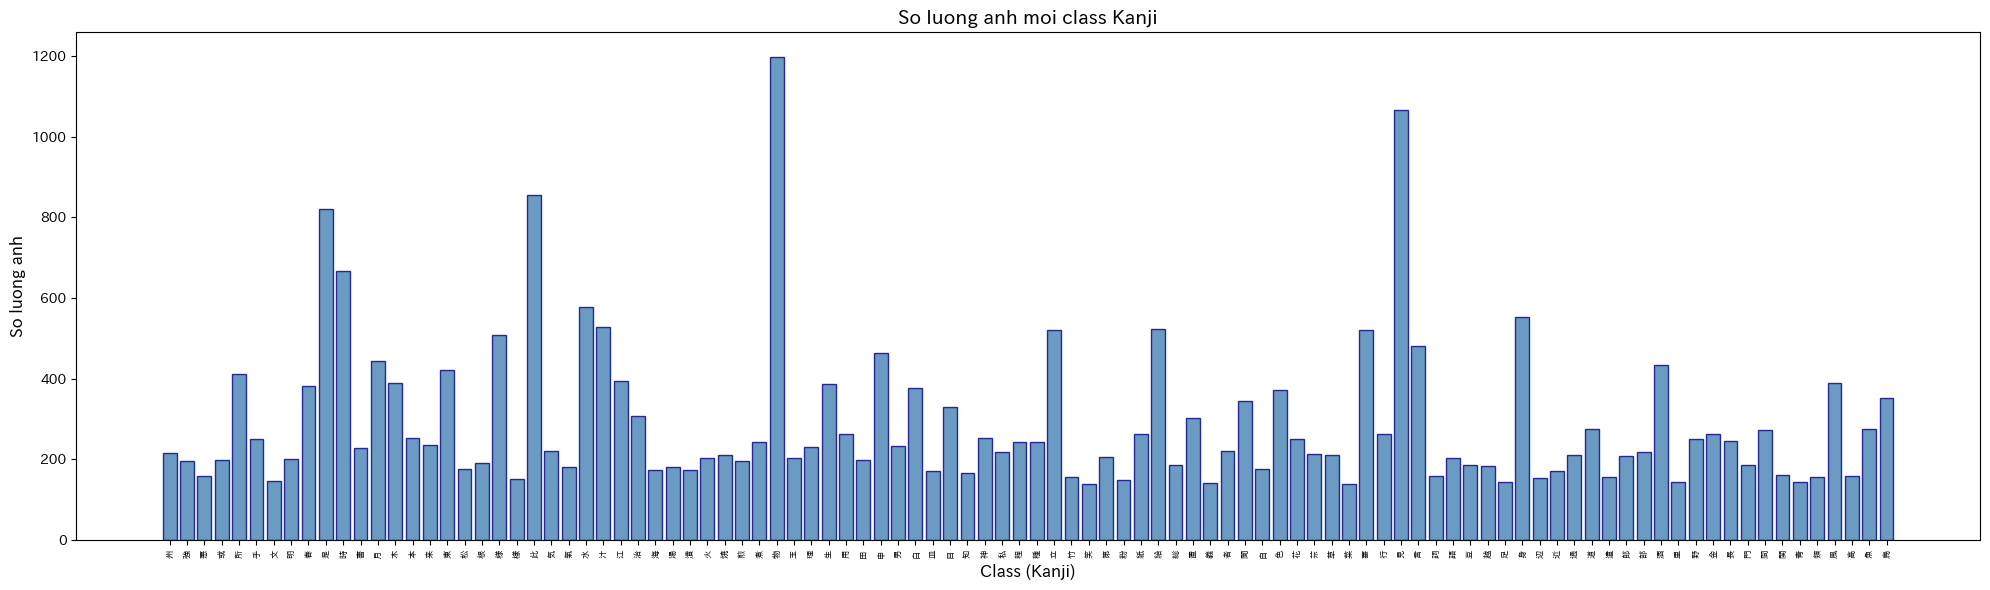


📈 Thống kê:
   Min: 139 ảnh/class
   Max: 1199 ảnh/class
   Trung bình: 293.6 ảnh/class


In [7]:
label_counts = Counter(labels)
counts = [label_counts[i] for i in range(len(class_names))]

plt.figure(figsize=(20, 6))
plt.bar(range(len(class_names)), counts, color='steelblue',
        edgecolor='navy', alpha=0.8)
plt.xlabel('Class (Kanji)', fontsize=12)
plt.ylabel('So luong anh', fontsize=12)
plt.title('So luong anh moi class Kanji', fontsize=14, fontweight='bold')
plt.xticks(range(len(class_names)), kanji_chars, fontsize=6, rotation=90)
plt.tight_layout()
plt.show()

print(f"\n📈 Thống kê:")
print(f"   Min: {min(counts)} ảnh/class")
print(f"   Max: {max(counts)} ảnh/class")
print(f"   Trung bình: {np.mean(counts):.1f} ảnh/class")

### 5.3 Hiển thị 10 ảnh ngẫu nhiên

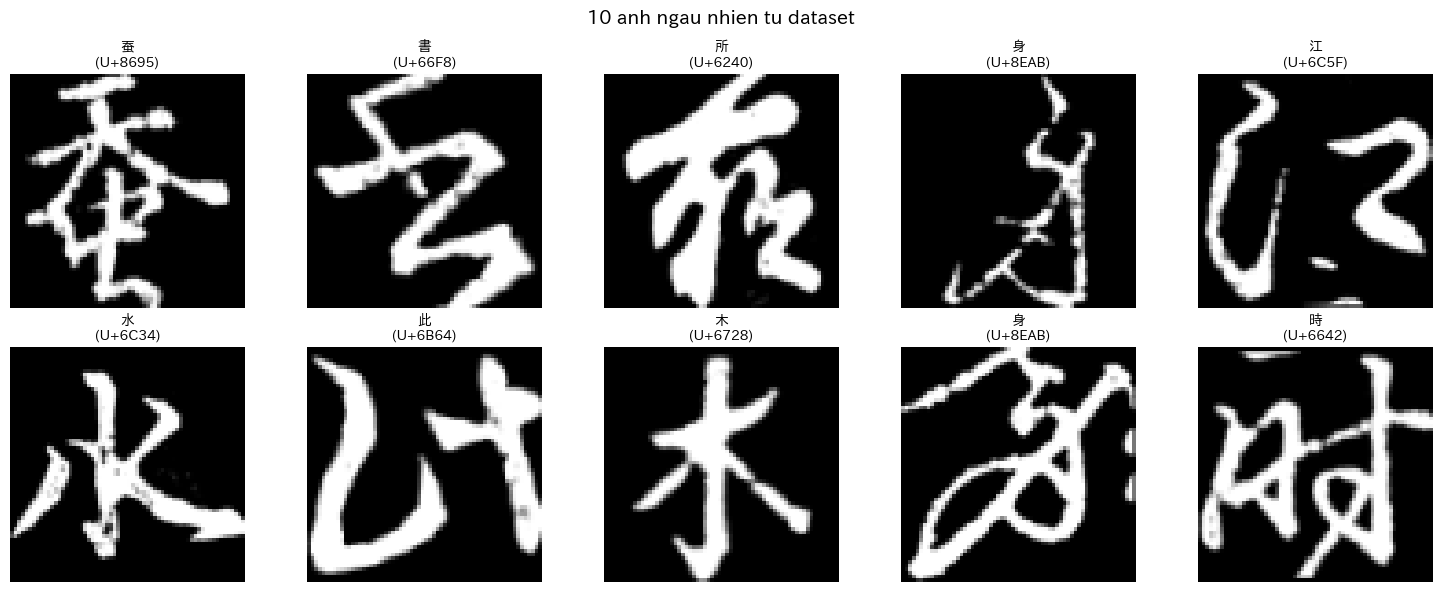

In [8]:
random_indices = random.sample(range(len(images)), 10)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('10 anh ngau nhien tu dataset', fontsize=14, fontweight='bold')

for i, idx in enumerate(random_indices):
    ax = axes[i // 5, i % 5]
    ax.imshow(images[idx].squeeze(), cmap='gray')
    kanji_label = unicode_to_kanji(class_names[labels[idx]])
    ax.set_title(f'{kanji_label}\n({class_names[labels[idx]]})', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

## 6. Chia dữ liệu: Train / Val / Test

In [9]:
X_train, X_temp, y_train, y_temp = train_test_split(
    images, labels, test_size=0.3, random_state=SEED, stratify=labels
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp
)

y_train_cat = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val_cat = keras.utils.to_categorical(y_val, NUM_CLASSES)
y_test_cat = keras.utils.to_categorical(y_test, NUM_CLASSES)

print("📊 Phân chia dữ liệu:")
print(f"   Tổng số ảnh: {len(images)}")
print(f"   Train: {len(X_train)} ảnh ({len(X_train)/len(images)*100:.1f}%)")
print(f"   Val:   {len(X_val)} ảnh ({len(X_val)/len(images)*100:.1f}%)")
print(f"   Test:  {len(X_test)} ảnh ({len(X_test)/len(images)*100:.1f}%)")
print(f"   Số class: {NUM_CLASSES}")

📊 Phân chia dữ liệu:
   Tổng số ảnh: 29365
   Train: 20555 ảnh (70.0%)
   Val:   4405 ảnh (15.0%)
   Test:  4405 ảnh (15.0%)
   Số class: 100


## 7. Data Augmentation bằng tf.data Pipeline

In [10]:
data_augmentation = keras.Sequential([
    layers.RandomRotation(factor=10/360, fill_mode='nearest'),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1, fill_mode='nearest'),
    layers.RandomZoom(height_factor=(-0.1, 0.1), fill_mode='nearest'),
], name='data_augmentation')

# Train: shuffle + batch + augmentation + prefetch
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train_cat))
train_ds = train_ds.shuffle(buffer_size=len(X_train), seed=SEED)
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE
)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

# Val & Test: chỉ batch + prefetch
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val_cat))
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test_cat))
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("✅ tf.data pipeline đã thiết lập")
print(f"   Train batches: {len(train_ds)}")
print(f"   Val batches:   {len(val_ds)}")
print(f"   Test batches:  {len(test_ds)}")
print(f"   Augmentation: rotation=±10°, translation=±10%, zoom=±10%")

✅ tf.data pipeline đã thiết lập
   Train batches: 643
   Val batches:   138
   Test batches:  138
   Augmentation: rotation=±10°, translation=±10%, zoom=±10%


## 8. Xây dựng mô hình CNN thuần (Custom CNN)

4 blocks: Conv2D×2 → BN → ReLU → MaxPool → Dropout(0.25)  
Flatten → Dense(512) → BN → ReLU → Dropout(0.5) → Dense(100, softmax)

In [11]:
def build_cnn(input_shape, num_classes):
    model = models.Sequential(name='Custom_CNN')

    # Block 1: 32 filters
    model.add(layers.Conv2D(32, (3,3), padding='same', kernel_initializer='he_normal', input_shape=input_shape))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Conv2D(32, (3,3), padding='same', kernel_initializer='he_normal'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2,2)))
    model.add(layers.Dropout(0.25))

    # Block 2: 64 filters
    model.add(layers.Conv2D(64, (3,3), padding='same', kernel_initializer='he_normal'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Conv2D(64, (3,3), padding='same', kernel_initializer='he_normal'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2,2)))
    model.add(layers.Dropout(0.25))

    # Block 3: 128 filters
    model.add(layers.Conv2D(128, (3,3), padding='same', kernel_initializer='he_normal'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Conv2D(128, (3,3), padding='same', kernel_initializer='he_normal'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2,2)))
    model.add(layers.Dropout(0.25))

    # Block 4: 256 filters
    model.add(layers.Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2,2)))
    model.add(layers.Dropout(0.25))

    # Classifier
    model.add(layers.Flatten())
    model.add(layers.Dense(512, kernel_initializer='he_normal'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(num_classes, activation='softmax'))

    return model

model = build_cnn(IMG_SHAPE, NUM_CLASSES)
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 16, 16, 128)    │             

 Total params: 3,326,532 (12.69 MB)

 Trainable params: 3,323,588 (12.68 MB)

 Non-trainable params: 2,944 (11.50 KB)

## 9. Compile & Training

In [12]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callback_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=7,
                            restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                patience=3, min_lr=1e-6, verbose=1)
]

print("✅ Model compiled")
print(f"   Optimizer: Adam (lr={LEARNING_RATE})")
print(f"   Loss: categorical_crossentropy")
print(f"   EarlyStopping: patience=7")
print(f"   ReduceLROnPlateau: factor=0.5, patience=3")

✅ Model compiled
   Optimizer: Adam (lr=0.001)
   Loss: categorical_crossentropy
   EarlyStopping: patience=7
   ReduceLROnPlateau: factor=0.5, patience=3


In [13]:
print("🚀 Bắt đầu training...")
print("=" * 60)

history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=callback_list,
    verbose=1
)

print(f"\n✅ Training hoàn tất! Epochs: {len(history.history['loss'])}")

🚀 Bắt đầu training...
Epoch 1/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 51s 45ms/step - accuracy: 0.4891 - loss: 2.1567 - val_accuracy: 0.8856 - val_loss: 0.4116 - learning_rate: 0.0010
Epoch 2/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.7929 - loss: 0.7695 - val_accuracy: 0.9480 - val_loss: 0.2046 - learning_rate: 0.0010
Epoch 3/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.8549 - loss: 0.5234 - val_accuracy: 0.9514 - val_loss: 0.1723 - learning_rate: 0.0010
Epoch 4/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.8889 - loss: 0.4090 - val_accuracy: 0.9637 - val_loss: 0.1288 - learning_rate: 0.0010
Epoch 5/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/step - accuracy: 0.9031 - loss: 0.3457 - val_accuracy: 0.9535 - val_loss: 0.1644 - learning_rate: 0.0010
Epoch 6/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.9166 - loss: 0.2923 - val_accuracy: 0.9687 - val_loss: 0.1123 - learning_rate: 0.0010
Epoch 7/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step 

## 10. Phân tích kết quả

### 10.1 Learning Curves

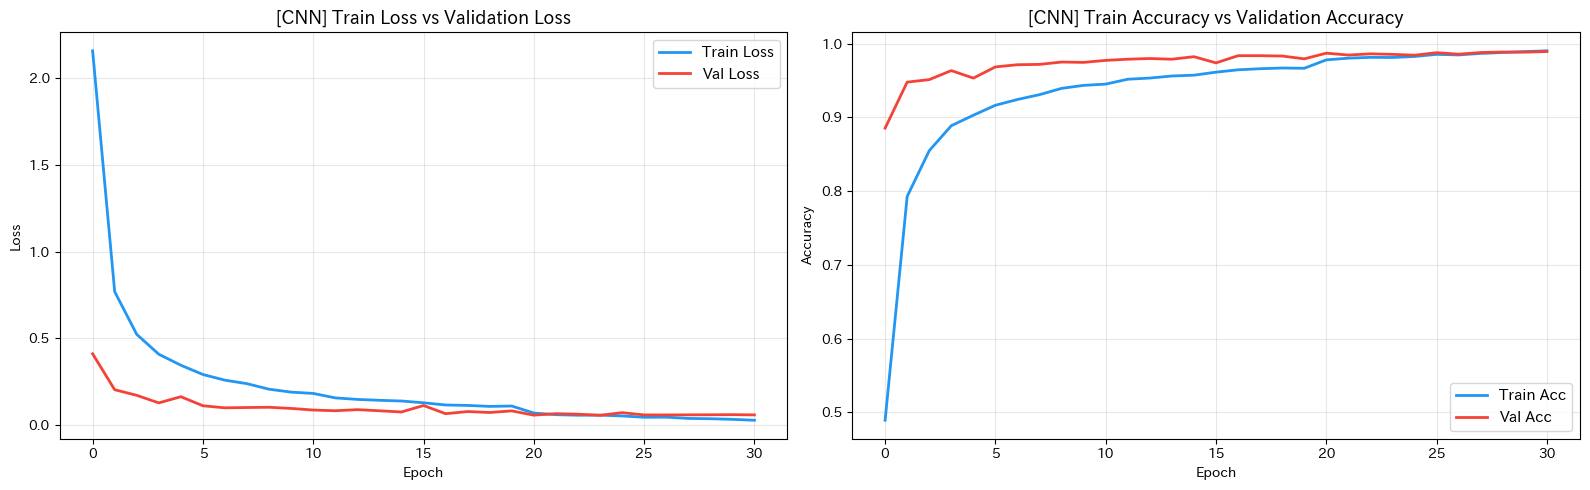

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2, color='#2196F3')
axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2, color='#F44336')
axes[0].set_title('[CNN] Train Loss vs Validation Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(fontsize=11); axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Train Acc', linewidth=2, color='#2196F3')
axes[1].plot(history.history['val_accuracy'], label='Val Acc', linewidth=2, color='#F44336')
axes[1].set_title('[CNN] Train Accuracy vs Validation Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend(fontsize=11); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 10.2 Đánh giá trên tập Test

In [15]:
test_loss, test_accuracy = model.evaluate(X_test, y_test_cat, verbose=1)
print(f"\n📊 Test Loss: {test_loss:.4f}  |  Test Accuracy: {test_accuracy*100:.2f}%")

138/138 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9852 - loss: 0.0597

📊 Test Loss: 0.0597  |  Test Accuracy: 98.52%


### 10.3 Classification Report

In [16]:
y_pred_proba = model.predict(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)

print("📋 Classification Report:")
print("=" * 80)
print(classification_report(y_test, y_pred, target_names=kanji_chars, digits=4))

138/138 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step
📋 Classification Report:
              precision    recall  f1-score   support

           州     1.0000    0.9697    0.9846        33
           強     0.9677    1.0000    0.9836        30
           悪     1.0000    1.0000    1.0000        24
           或     1.0000    1.0000    1.0000        30
           所     0.9841    1.0000    0.9920        62
           手     1.0000    1.0000    1.0000        38
           文     1.0000    1.0000    1.0000        22
           明     1.0000    0.9667    0.9831        30
           春     0.9811    0.9123    0.9455        57
           是     0.9919    1.0000    0.9960       123
           時     0.9901    1.0000    0.9950       100
           書     0.9412    0.9412    0.9412        34
           月     1.0000    0.9091    0.9524        66
           木     1.0000    0.9655    0.9825        58
           本     1.0000    0.9737    0.9867        38
           来     0.9714    0.9714    0.9714        35
           東  

### 10.4 Confusion Matrix (Top 15 tốt nhất & kém nhất)

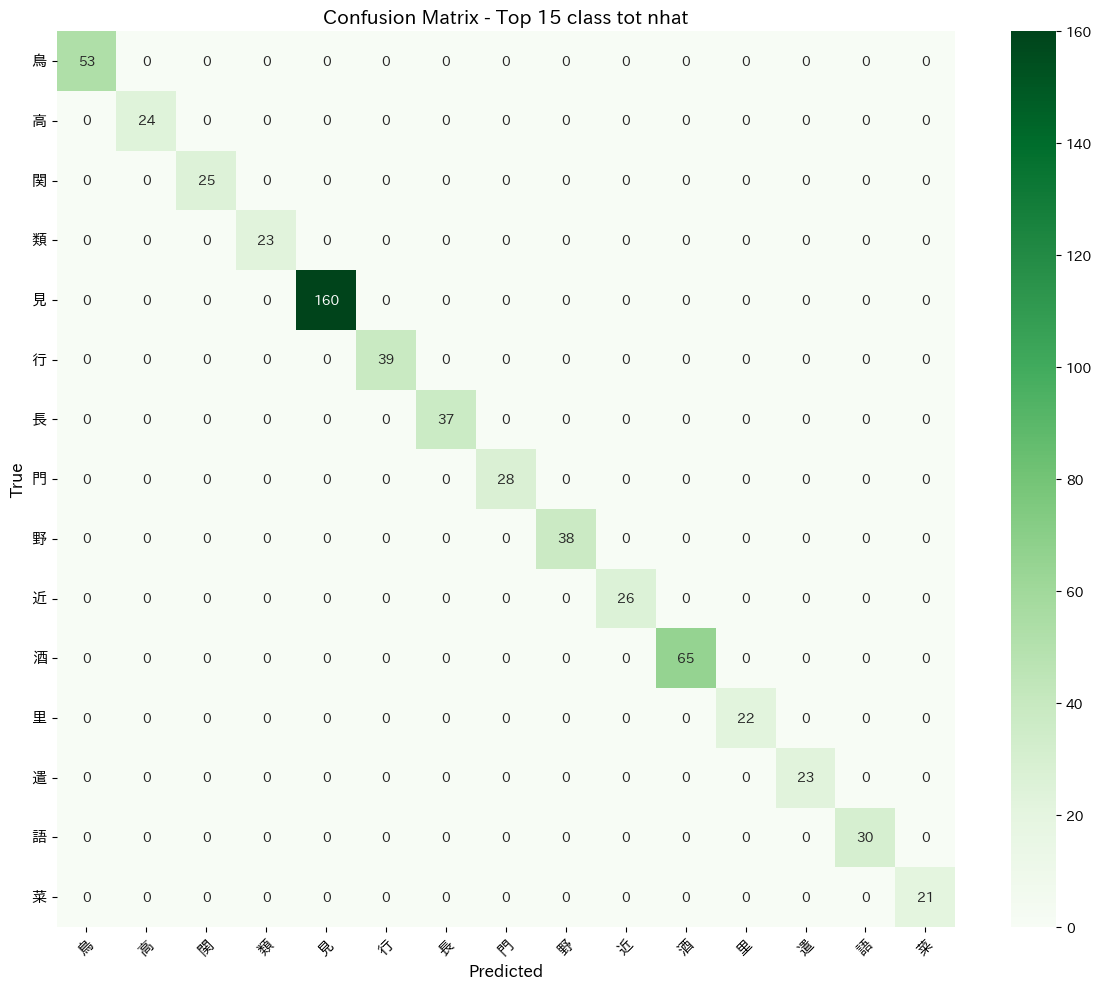


✅ Top 15 class tốt nhất:
   鳥 (U+9CE5): 100.00%
   高 (U+9AD8): 100.00%
   関 (U+95A2): 100.00%
   類 (U+985E): 100.00%
   見 (U+898B): 100.00%
   行 (U+884C): 100.00%
   長 (U+9577): 100.00%
   門 (U+9580): 100.00%
   野 (U+91CE): 100.00%
   近 (U+8FD1): 100.00%
   酒 (U+9152): 100.00%
   里 (U+91CC): 100.00%
   遣 (U+9063): 100.00%
   語 (U+8A9E): 100.00%
   菜 (U+83DC): 100.00%


In [30]:
cm = confusion_matrix(y_test, y_pred)

class_correct = cm.diagonal()
class_total = cm.sum(axis=1)
class_accuracy = np.divide(class_correct, class_total,
                           out=np.zeros_like(class_correct, dtype=float),
                           where=class_total != 0)

# ===== Top 15 tốt nhất =====
best_indices = np.argsort(class_accuracy)[-15:][::-1]
cm_best = cm[np.ix_(best_indices, best_indices)]
labels_best = [kanji_chars[i] for i in best_indices]

plt.figure(figsize=(12, 10))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Greens',
            xticklabels=labels_best, yticklabels=labels_best)
plt.title('Confusion Matrix - Top 15 class tot nhat', fontsize=14, fontweight='bold')
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('True', fontsize=12)
plt.xticks(fontsize=11, rotation=45)
plt.yticks(fontsize=11, rotation=0)
plt.tight_layout()
plt.show()

print("\n✅ Top 15 class tốt nhất:")
for idx in best_indices:
    print(f"   {unicode_to_kanji(class_names[idx])} ({class_names[idx]}): {class_accuracy[idx]*100:.2f}%")

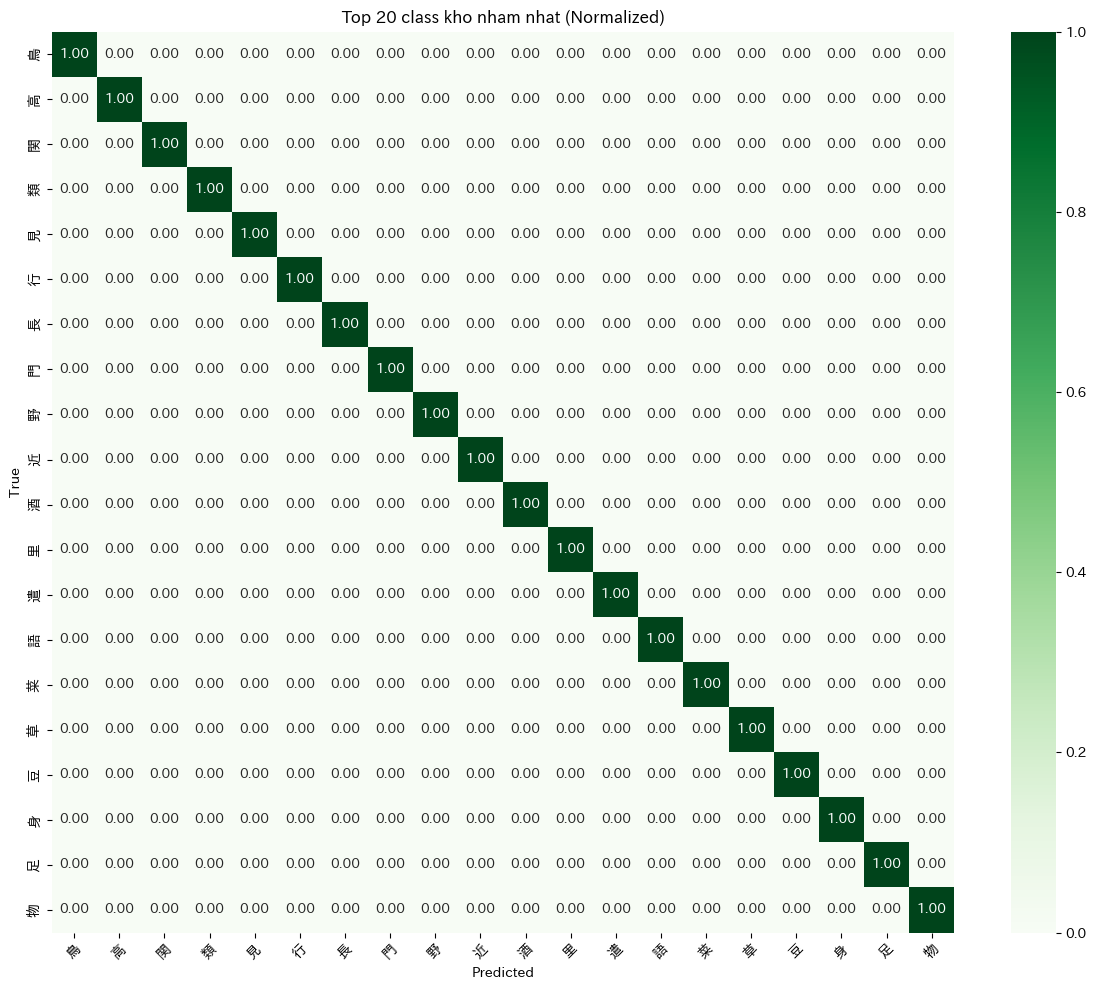

In [29]:
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# lấy top 20 class tốt nhất
class_accuracy = np.diag(cm_norm)
best_indices = np.argsort(class_accuracy)[-20:][::-1]

cm_best = cm_norm[np.ix_(best_indices, best_indices)]
labels_best = [kanji_chars[i] for i in best_indices]

plt.figure(figsize=(12, 10))
sns.heatmap(cm_best, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=labels_best, yticklabels=labels_best)

plt.title('Top 20 class kho nham nhat (Normalized)', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

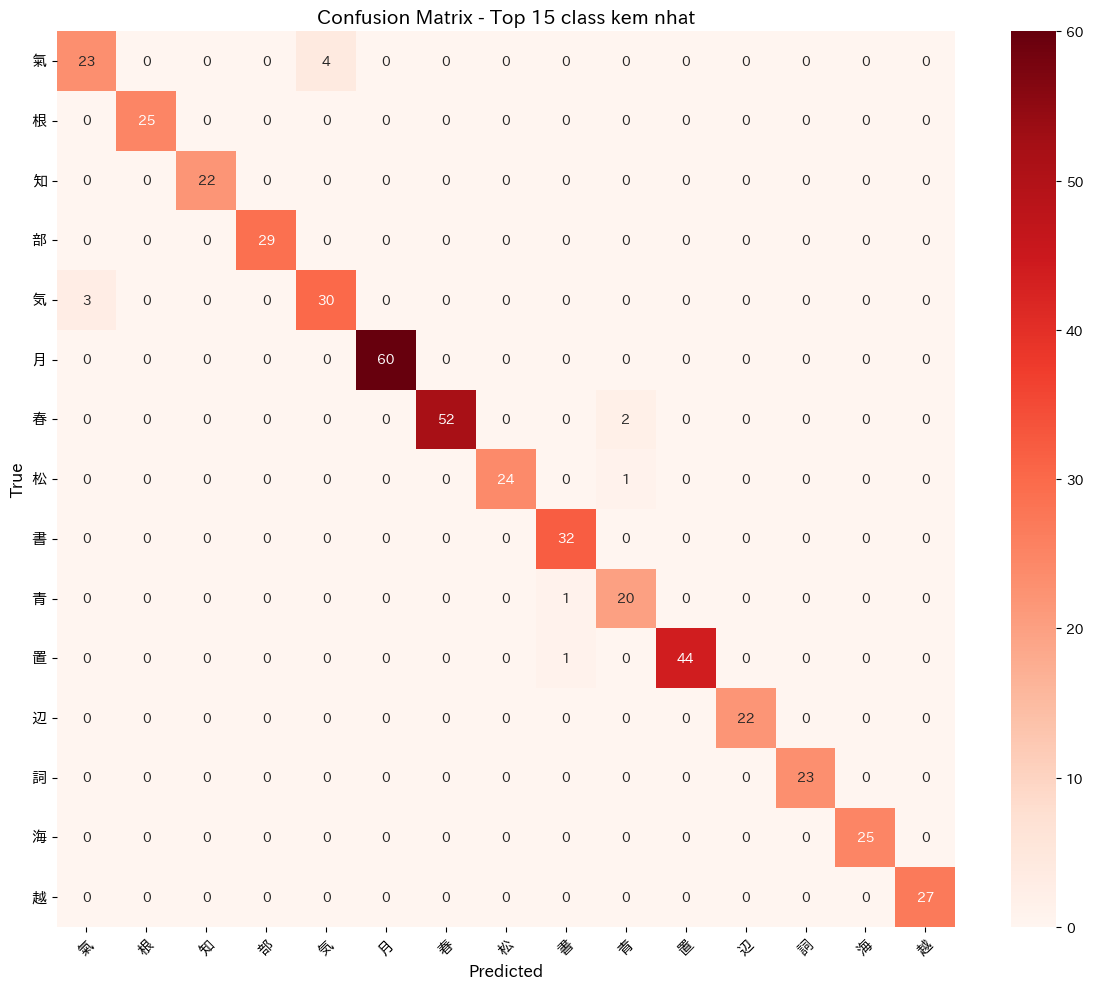


❌ Top 15 class kém nhất:
   氣 (U+6C23): 85.19%
   根 (U+6839): 86.21%
   知 (U+77E5): 88.00%
   部 (U+90E8): 90.62%
   気 (U+6C17): 90.91%
   月 (U+6708): 90.91%
   春 (U+6625): 91.23%
   松 (U+677E): 92.31%
   書 (U+66F8): 94.12%
   青 (U+9752): 95.24%
   置 (U+7F6E): 95.65%
   辺 (U+8FBA): 95.65%
   詞 (U+8A5E): 95.83%
   海 (U+6D77): 96.15%
   越 (U+8D8A): 96.43%


In [32]:
# ===== Top 15 kém nhất =====
worst_indices = np.argsort(class_accuracy)[:15]
cm_worst = cm[np.ix_(worst_indices, worst_indices)]
labels_worst = [kanji_chars[i] for i in worst_indices]

plt.figure(figsize=(12, 10))
sns.heatmap(cm_worst, annot=True, fmt='d', cmap='Reds',
            xticklabels=labels_worst, yticklabels=labels_worst)
plt.title('Confusion Matrix - Top 15 class kem nhat', fontsize=14, fontweight='bold')
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('True', fontsize=12)
plt.xticks(fontsize=11, rotation=45)
plt.yticks(fontsize=11, rotation=0)
plt.tight_layout()
plt.show()

print("\n❌ Top 15 class kém nhất:")
for idx in worst_indices:
    print(f"   {unicode_to_kanji(class_names[idx])} ({class_names[idx]}): {class_accuracy[idx]*100:.2f}%")


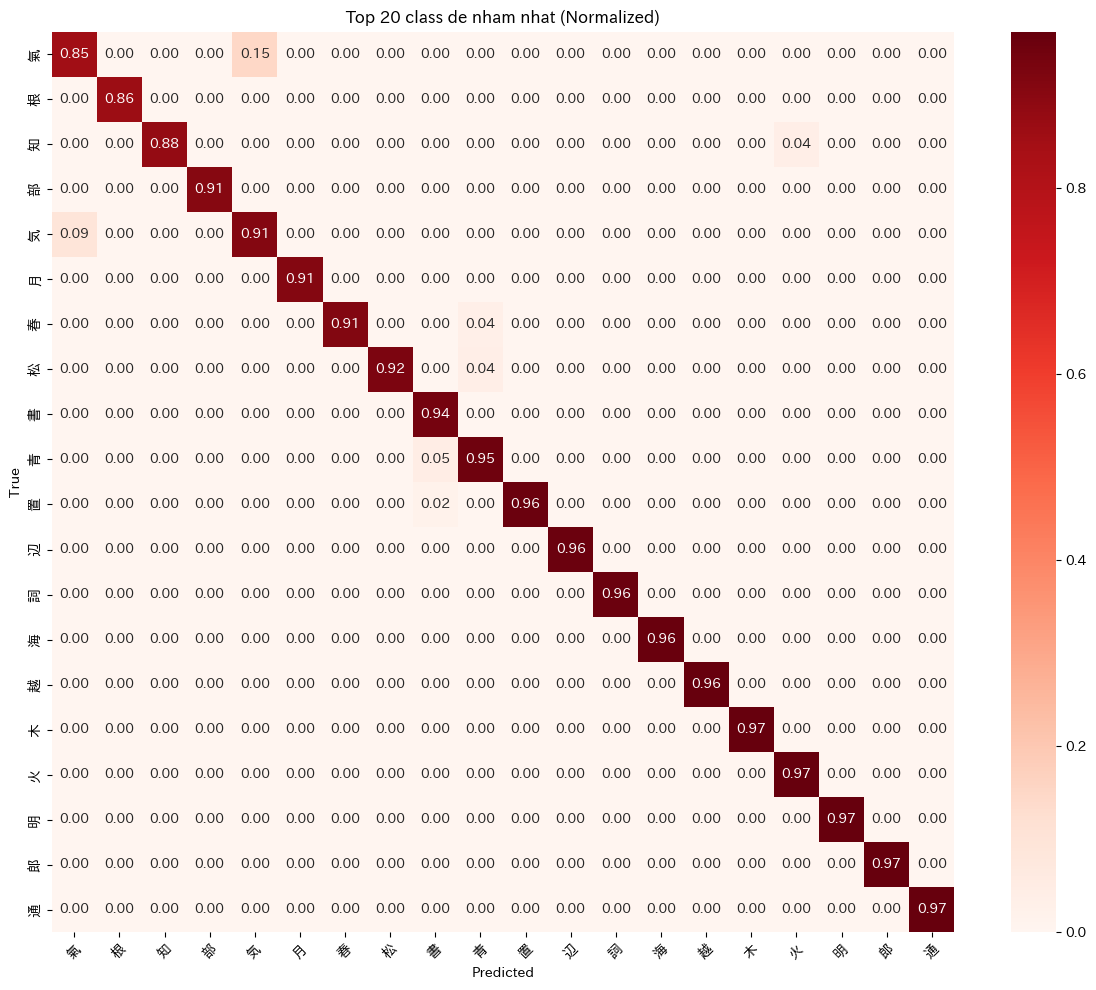

In [31]:
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# ❗ lấy 20 class có accuracy thấp nhất
class_accuracy = np.diag(cm_norm)
worst_indices = np.argsort(class_accuracy)[:20]

cm_worst = cm_norm[np.ix_(worst_indices, worst_indices)]
labels_worst = [kanji_chars[i] for i in worst_indices]

plt.figure(figsize=(12, 10))
sns.heatmap(cm_worst, annot=True, fmt='.2f', cmap='Reds',
            xticklabels=labels_worst, yticklabels=labels_worst)

plt.title('Top 20 class de nham nhat (Normalized)', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 10.5 Tổng kết

In [19]:
correct = np.trace(cm)
total = np.sum(cm)
print(f"📊 Tổng kết:")
print(f"   Đúng: {correct}/{total} ({correct/total*100:.2f}%)")
print(f"   Sai:  {total-correct}/{total} ({(total-correct)/total*100:.2f}%)")
print(f"   Mean per-class accuracy:   {np.mean(class_accuracy)*100:.2f}%")
print(f"   Median per-class accuracy: {np.median(class_accuracy)*100:.2f}%")

📊 Tổng kết:
   Đúng: 4340/4405 (98.52%)
   Sai:  65/4405 (1.48%)
   Mean per-class accuracy:   98.26%
   Median per-class accuracy: 100.00%


## 11. Lưu Model & Labels

In [20]:
# ==================== LƯU MODEL ====================
save_path = os.path.join(SAVE_DIR, 'model_cnn.h5')
model.save(save_path)
print(f"💾 Model đã lưu: {save_path}")
print(f"   Kích thước: {os.path.getsize(save_path) / (1024*1024):.2f} MB")

# ==================== LƯU LABELS ====================
# Lưu mapping: index -> tên folder (U+XXXX) -> ký tự Kanji
# File này dùng cho demo sau này
label_data = {
    'class_names': class_names,          # ['U+4E00', 'U+4E8C', ...]
    'kanji_chars': kanji_chars,           # ['一', '二', ...]
    'num_classes': NUM_CLASSES,
    'img_size': IMG_SIZE,
    'input_shape': list(IMG_SHAPE),       # [64, 64, 1]
    'index_to_unicode': {str(i): class_names[i] for i in range(len(class_names))},
    'index_to_kanji': {str(i): kanji_chars[i] for i in range(len(kanji_chars))}
}

label_path = os.path.join(SAVE_DIR, 'labelscnn.json')
with open(label_path, 'w', encoding='utf-8') as f:
    json.dump(label_data, f, ensure_ascii=False, indent=2)

print(f"\n🏷️ Labels đã lưu: {label_path}")
print(f"   Số class: {len(class_names)}")
print(f"   Ví dụ: index 0 -> {class_names[0]} -> {kanji_chars[0]}")
print(f"   Ví dụ: index 1 -> {class_names[1]} -> {kanji_chars[1]}")

💾 Model đã lưu: /content/drive/MyDrive/dataset/model_cnn.h5
   Kích thước: 38.22 MB

🏷️ Labels đã lưu: /content/drive/MyDrive/dataset/labelscnn.json
   Số class: 100
   Ví dụ: index 0 -> U+5DDE -> 州
   Ví dụ: index 1 -> U+5F37 -> 強


## 12. Tổng kết

In [21]:
print("=" * 60)
print("TỔNG KẾT - CUSTOM CNN")
print("=" * 60)
print(f"   Model:          Custom CNN (4 blocks x 2 Conv)")
print(f"   Input shape:    {IMG_SHAPE}")
print(f"   Num classes:    {NUM_CLASSES}")
print(f"   Total params:   {model.count_params():,}")
print(f"   Epochs trained: {len(history.history['loss'])}")
print(f"   Test Loss:      {test_loss:.4f}")
print(f"   Test Accuracy:  {test_accuracy*100:.2f}%")
print(f"   Model saved:    {save_path}")
print(f"   Labels saved:   {label_path}")
print("=" * 60)

TỔNG KẾT - CUSTOM CNN
   Model:          Custom CNN (4 blocks x 2 Conv)
   Input shape:    (64, 64, 1)
   Num classes:    100
   Total params:   3,326,532
   Epochs trained: 31
   Test Loss:      0.0597
   Test Accuracy:  98.52%
   Model saved:    /content/drive/MyDrive/dataset/model_cnn.h5
   Labels saved:   /content/drive/MyDrive/dataset/labelscnn.json
